<a href="https://colab.research.google.com/github/Mich-088/MAT422/blob/main/HW_3_5_3_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HOMEWORK 3.5, 3.6

*   3.5 K-means
*   3.6 Support Vector Machine

---


<span style="color:blue">**3.5 K-means:**</span>



---



In [247]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_classification
from sklearn.cluster import KMeans
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

np.set_printoptions(precision=4, suppress=True)

Cluster centers:
[[-9.7182  9.0864]
 [ 6.1952 -4.6704]
 [ 1.0144  2.5323]
 [-0.3031 -3.9234]]
Inertia: 184.72495649082438


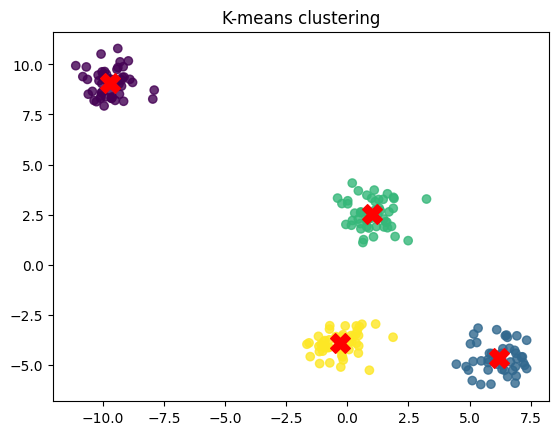

In [248]:
X, true_labels = make_blobs(n_samples=200, centers=4 , cluster_std=0.7, random_state=175)
kmeans = KMeans(n_clusters=4, n_init=10, random_state=320)
cluster_labels = kmeans.fit_predict(X)

print("Cluster centers:")
print(kmeans.cluster_centers_)
print("Inertia:", kmeans.inertia_)

plt.scatter(X[:,0], X[:,1], c=cluster_labels, cmap="viridis", alpha=0.8)
plt.scatter(kmeans.cluster_centers_[:,0], kmeans.cluster_centers_[:,1], marker="X", s=200, color="red")
plt.title("K-means clustering")
plt.show()

k-means clustering is a popular method of vector quantization that aims to
partition n observations into k clusters in which each observation belongs
to the cluster with the nearest mean (cluster centers or cluster centroid),
serving as a prototype of the cluster.  Unlike a SVG which is a supervised learning algorithm, k-means is an unsupervised learning algorithm.

Above, 200 random data points are clustered into four clusters.  The x's represent the cluster centers.  

<span style="color:blue">**3.6 Support Vector Machine:**</span>


---

Training accuracy: 0.9933333333333333
Number of support vectors: [5 4]


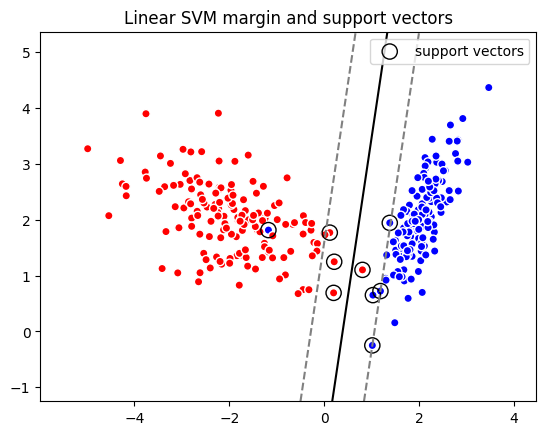

In [249]:
Xc, yc = make_classification(n_samples=300, n_features=2, n_redundant=0, n_informative=2,
                             n_clusters_per_class=1, class_sep=2.0, random_state=600)
svm = SVC(kernel="linear", C=1.5)
svm.fit(Xc, yc)
pred = svm.predict(Xc)

print("Training accuracy:", accuracy_score(yc, pred))
print("Number of support vectors:", svm.n_support_)

xx, yy = np.meshgrid(np.linspace(Xc[:,0].min()-1, Xc[:,0].max()+1, 150),
                     np.linspace(Xc[:,1].min()-1, Xc[:,1].max()+1, 150))
Z = svm.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.contour(xx, yy, Z, levels=[-1, 0, 1], colors=["gray", "black", "gray"], linestyles=["--", "-", "--"])
plt.scatter(Xc[:,0], Xc[:,1], c=yc, cmap="bwr", edgecolor="white")
plt.scatter(svm.support_vectors_[:,0], svm.support_vectors_[:,1], s=120, facecolors="none", edgecolors="black", label="support vectors")
plt.title("Linear SVM margin and support vectors")
plt.legend()
plt.show()

In the above code we have a SVM or a supervised machine learning algorithm.  SVM in machine learning aim to analyze data for classification and regression.  The objective of the support vector machine algorithm is to find a hyperplane in a high-dimensional space of the number of features that distinctly classifies the data points.  One category is represented in red and the other in blue.  Predictions of new data are based on which side of the gap they fall.

Above, 300 data points belonging to thiose two different categories.  The code "class_sep=1.5" controls how separated the two classes or categories are.  The SVM tries to find the best straight line to separate the two classes.  The code includes a part where the proportion of points classified correctly is calculated.  The solid line represents the boundary the SVM decided on.  The dashed lines are margins on either side of the decision boundary.